# 26.04 Act 3: From two models to one retention decision, Online Retail II
Question: if a retailer had a fixed retention budget, which customers should it spend it on, and how much would it expect to get back?
Act 1 told us who tends to leave and Act 2 told us what a customer is worth. Act 3 puts the two side by side, shows the maths of a budget, and says what the result cannot tell you.
Everything is revenue in GBP, not profit. The budget, the cost per contact and the save rate are assumptions named in one cell, not facts from the data.
Out of scope: why customers leave, and any real intervention design.

In [1]:
import zipfile, os
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy.special import betaln
from lifetimes import BetaGeoFitter
from lifetimes.utils import calibration_and_holdout_data, summary_data_from_transaction_data
%matplotlib inline

np.random.seed(42)
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")   # run from the repo root so data/ and outputs/ resolve
os.makedirs("outputs", exist_ok=True)
T_END = pd.Timestamp("2011-12-09")
HOLDOUT_DAYS = 180
CAL_END = T_END - pd.Timedelta(f"{HOLDOUT_DAYS}D")
HORIZON_MONTHS = 12                    # same CLV horizon as Act 2
DISCOUNT_ANNUAL = 0.10                 # same discount rate as Act 2
DISC_MONTHLY = (1 + DISCOUNT_ANNUAL) ** (1 / 12) - 1
RISK_DAYS = 365                        # churn risk = chance of NO order in the next 365 days
RISK_BANDS = [0.25, 0.60]              # low below 25%, mid 25% to 60%, high above 60%
# the three assumptions the allocation rests on (all invented, see the limitations)
BUDGET = 50_000                        # GBP for the 12 months, about 0.6 percent of total 12-month CLV
COST_PER_CONTACT = 25                  # GBP per customer contacted (an offer plus a call)
SAVE_RATE = 0.15                       # share of would-be-lost customers an intervention keeps
LOG = {}
print("budget", BUDGET, "| cost per contact", COST_PER_CONTACT, "| save rate", SAVE_RATE, "| risk window", RISK_DAYS, "days")

budget 50000 | cost per contact 25 | save rate 0.15 | risk window 365 days


/tmp/ipykernel_7240/1661596056.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  CAL_END = T_END - pd.Timedelta(f"{HOLDOUT_DAYS}D")


## Step 1. Same cleaned order table as Acts 1 and 2
Identical cleaning rules, so all three acts describe the same customers. Counts are printed so they can be checked against `DATA.md`.

In [2]:
PKL = "data/retail_raw.pkl"
if os.path.exists(PKL):
    raw = pd.read_pickle(PKL)
else:
    with zipfile.ZipFile("data/online_retail_II.zip") as z:
        xl = [n for n in z.namelist() if n.endswith(".xlsx")][0]
        z.extract(xl, "data")
    raw = pd.concat(pd.read_excel(os.path.join("data", xl), sheet_name=None).values(), ignore_index=True)
    raw.to_pickle(PKL)
df = raw.loc[raw["Customer ID"].notna()].copy()
df["Customer ID"] = df["Customer ID"].astype(int)
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
NON_PRODUCT = {"POST","D","M","C2","BANK CHARGES","ADJUST","ADJUST2","S","AMAZONFEE","DOT","CRUK","TEST001","TEST002","PADS","B"}
for name, f in [("cancellation invoice", lambda d: d["Invoice"].str.startswith("C")),
                ("Quantity <= 0",        lambda d: d["Quantity"] <= 0),
                ("Price <= 0",           lambda d: d["Price"] <= 0),
                ("non-product StockCode",lambda d: d["StockCode"].str.upper().isin(NON_PRODUCT))]:
    m = f(df); print(f"{name}: removed {m.sum():,}"); df = df.loc[~m]
df["Date"] = df["InvoiceDate"].dt.normalize()
df["Revenue"] = df["Quantity"] * df["Price"]
tx = (df.groupby(["Customer ID", "Date"], as_index=False)["Revenue"].sum().rename(columns={"Revenue": "Value"}))
print("clean rows:", len(df), "| order days:", len(tx), "| customers:", tx["Customer ID"].nunique())
LOG["clean_rows"] = len(df); LOG["customers"] = int(tx["Customer ID"].nunique())

cancellation invoice: removed 18,744
Quantity <= 0: removed 0
Price <= 0: removed 71
non-product StockCode: removed 2,915


clean rows: 802634 | order days: 32878 | customers: 5852


## Step 2. Rebuild the Act 2 CLV
BG/NBD on all orders to 2011-12-09, order value = each customer's own average repeat order (repeater average for one-order customers), 12 months, 10 percent discount. The total must come back to the Act 2 figure of GBP 8,888,115, which is the check that this is the same model.

In [3]:
full = summary_data_from_transaction_data(tx, "Customer ID", "Date", observation_period_end=T_END,
                                          freq="D", monetary_value_col="Value")
bgf = BetaGeoFitter(penalizer_coef=0.001).fit(full["frequency"], full["recency"], full["T"])
POP_AOV = float(full.loc[full["frequency"] > 0, "monetary_value"].mean())
full["aov"] = np.where(full["frequency"] > 0, full["monetary_value"], POP_AOV)
full["clv"] = 0.0
for m in range(1, HORIZON_MONTHS + 1):
    n = (bgf.predict(30 * m, full["frequency"], full["recency"], full["T"])
         - bgf.predict(30 * (m - 1), full["frequency"], full["recency"], full["T"]))
    full["clv"] += full["aov"] * n / (1 + DISC_MONTHLY) ** m
full["p_alive"] = bgf.conditional_probability_alive(full["frequency"], full["recency"], full["T"])
print(f"customers {len(full):,} | total 12-month CLV {full['clv'].sum():,.0f} (Act 2: 8,888,115)")
full["tier"] = pd.qcut(full["clv"].rank(method="first"), 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 top"])
LOG["total_clv"] = float(full["clv"].sum())

customers 5,852 | total 12-month CLV 8,888,115 (Act 2: 8,888,115)


## Step 3. Churn risk as one plain number
Act 1's Cox model was fitted only on 3,016 newer customers using first-30-day covariates, so it cannot score the whole base. BG/NBD can, and it is the same model that produced CLV.
Churn risk here is the probability a customer places no order in the next 365 days. It has two parts: already gone (1 minus probability alive), plus still alive today but silent for the whole year. Both parts have an exact formula under BG/NBD, no simulation. The saveable part is the second one: a customer who has already left cannot be kept.
Check first that the formula reproduces the library's probability alive.

In [4]:
def risk_parts(params, x, tx_, T_, t):
    """Exact BG/NBD: probability alive now, and probability alive now AND no order in the next t days."""
    r, al, a, b = params["r"], params["alpha"], params["a"], params["b"]
    x = np.asarray(x, float); tx_ = np.asarray(tx_, float); T_ = np.asarray(T_, float)
    lA = betaln(a, b + x) - (x + r) * np.log(al + T_)                      # alive at T
    with np.errstate(divide="ignore", invalid="ignore"):
        lD = np.where(x > 0, betaln(a + 1, b + x - 1) - (x + r) * np.log(al + tx_), -np.inf)   # dropped after last order
    lQ = betaln(a, b + x) - (x + r) * np.log(al + T_ + t)                  # alive and silent for t more days
    tot = np.logaddexp(lA, lD)
    return np.exp(lA - tot), np.exp(lQ - tot)

pa, q = risk_parts(bgf.params_, full["frequency"], full["recency"], full["T"], RISK_DAYS)
print("largest gap to the library's probability alive:", float(np.abs(pa - full["p_alive"]).max()))
full["q_saveable"] = q                       # still alive today, silent for 365 days
full["risk"] = (1 - pa) + q                  # no order in the next 365 days
print(full[["p_alive", "q_saveable", "risk"]].describe().round(3).to_string())

largest gap to the library's probability alive: 1.1302070390684094e-13
        p_alive  q_saveable      risk
count  5852.000    5852.000  5852.000
mean      0.909       0.267     0.358
std       0.174       0.253     0.272
min       0.000       0.000     0.000
25%       0.923       0.041     0.090
50%       0.979       0.189     0.336
75%       1.000       0.422     0.618
max       1.000       0.777     1.000


## Step 4. Did that risk number hold up on days it never saw?
Same trick as Act 2. Fit on data to 2011-06-12, compute each customer's chance of no order in the next 180 days, then compare with what really happened. Customers are cut into ten equal groups from lowest to highest predicted risk.

customers 4,952 | predicted share silent 48.3% | actual 48.1%
        customers  predicted  actual
decile                              
1             496      0.034   0.034
2             495      0.140   0.123
3             495      0.267   0.234
4             495      0.380   0.392
5             495      0.483   0.444
6             495      0.570   0.576
7             495      0.651   0.655
8             495      0.712   0.705
9             495      0.765   0.776
10            496      0.831   0.869
      customers  predicted  actual
band                              
low        1183      0.109   0.101
mid        1700      0.438   0.422
high       2069      0.734   0.746


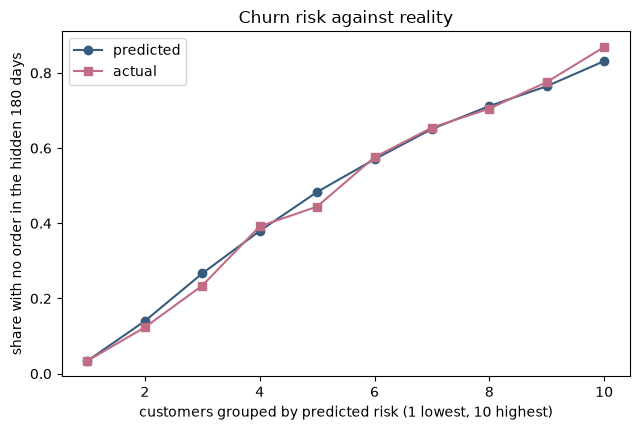

In [5]:
cal = calibration_and_holdout_data(tx, "Customer ID", "Date", calibration_period_end=CAL_END,
        observation_period_end=T_END, freq="D", monetary_value_col="Value")
bgc = BetaGeoFitter(penalizer_coef=0.001).fit(cal["frequency_cal"], cal["recency_cal"], cal["T_cal"])
pa_c, q_c = risk_parts(bgc.params_, cal["frequency_cal"], cal["recency_cal"], cal["T_cal"], HOLDOUT_DAYS)
cal["risk"] = (1 - pa_c) + q_c
cal["silent"] = (cal["frequency_holdout"] == 0).astype(float)
print(f"customers {len(cal):,} | predicted share silent {cal['risk'].mean():.1%} | actual {cal['silent'].mean():.1%}")
cal["decile"] = pd.qcut(cal["risk"].rank(method="first"), 10, labels=False) + 1
bt = cal.groupby("decile").agg(customers=("risk", "size"), predicted=("risk", "mean"), actual=("silent", "mean"))
print(bt.round(3).to_string())
cal["band"] = pd.cut(cal["risk"], [-1] + RISK_BANDS + [1.01], labels=["low", "mid", "high"])
bb = cal.groupby("band", observed=True).agg(customers=("risk", "size"), predicted=("risk", "mean"), actual=("silent", "mean"))
print(bb.round(3).to_string())
fig, ax = plt.subplots(figsize=(6.5, 4.4))
ax.plot(bt.index, bt["predicted"], marker="o", color="#355c7d", label="predicted")
ax.plot(bt.index, bt["actual"], marker="s", color="#c06c84", label="actual")
ax.set_xlabel("customers grouped by predicted risk (1 lowest, 10 highest)")
ax.set_ylabel("share with no order in the hidden 180 days"); ax.legend(); ax.set_title("Churn risk against reality")
fig.tight_layout(); fig.savefig("outputs/07_risk_backtest.png", dpi=150); plt.show()
LOG["bt_pred"] = float(cal["risk"].mean()); LOG["bt_act"] = float(cal["silent"].mean())
LOG["bt_bands"] = bb.reset_index().astype({"band": str}).to_dict("records")

## Step 5. What a customer is worth if we keep them, and what is at stake
CLV from Act 2 already contains the chance that the customer leaves, so it is not the right prize for a save. The prize for keeping a customer is what they would bring if they stay active at their own pace for the year.
That is their average order value times their expected order rate while alive times 365 days (value if kept, undiscounted, a stated simplification). Value at stake = saveable risk x value if kept. This is the revenue an intervention could actually recover.

In [6]:
lam_alive = (full["frequency"] + bgf.params_["r"]) / (bgf.params_["alpha"] + full["T"])   # orders per day while alive
full["value_if_kept"] = full["aov"] * lam_alive * RISK_DAYS
full["at_stake"] = full["q_saveable"] * full["value_if_kept"]
print(full[["clv", "value_if_kept", "at_stake"]].describe().round(0).to_string())
print(f"total 12-month CLV {full['clv'].sum():,.0f} | total value at stake {full['at_stake'].sum():,.0f} "
      f"({full['at_stake'].sum() / full['clv'].sum():.1%} of CLV)")
rho = full["risk"].corr(full["clv"], method="spearman")
print(f"rank correlation between churn risk and CLV: {rho:.2f}")
LOG["at_stake"] = float(full["at_stake"].sum()); LOG["rho"] = float(rho)

            clv  value_if_kept  at_stake
count    5852.0         5852.0    5852.0
mean     1519.0         1769.0     141.0
std      7688.0         8622.0    1152.0
min         0.0            5.0       0.0
25%       211.0          253.0      36.0
50%       516.0          664.0      99.0
75%      1259.0         1497.0     161.0
max    324678.0       382304.0   85992.0
total 12-month CLV 8,888,115 | total value at stake 826,741 (9.3% of CLV)
rank correlation between churn risk and CLV: -0.86


## Step 6. The cross-tab: churn risk band by CLV tier
Rows are risk bands (low, mid, high by the 365-day risk), columns are the Act 2 value quartiles. Each cell shows how many customers, their average risk, their total CLV and the total value at stake.

In [7]:
full["band"] = pd.cut(full["risk"], [-1] + RISK_BANDS + [1.01], labels=["low", "mid", "high"])
g = full.groupby(["band", "tier"], observed=True).agg(customers=("clv", "size"), mean_risk=("risk", "mean"),
        total_clv=("clv", "sum"), mean_value_if_kept=("value_if_kept", "mean"), at_stake=("at_stake", "sum"))
g["share_of_at_stake"] = g["at_stake"] / g["at_stake"].sum()
print(g.round(3).to_string())
print()
print("customers per cell"); print(g["customers"].unstack().to_string())
print("value at stake per cell (GBP)"); print(g["at_stake"].unstack().round(0).to_string())
hh = g.loc[("high", "Q4 top")]
print(f"\nhigh risk x top value cell: {int(hh['customers'])} customers, {hh['share_of_at_stake']:.1%} of value at stake")
LOG["cells"] = g.reset_index().astype({"band": str, "tier": str}).to_dict("records")

                customers  mean_risk    total_clv  mean_value_if_kept    at_stake  share_of_at_stake
band tier                                                                                           
low  Q1 lowest         35      0.174     5193.418             173.360     746.726              0.001
     Q2               279      0.171   105371.318             434.692   14714.105              0.018
     Q3               809      0.117   701447.224             987.547   59557.881              0.072
     Q4 top          1352      0.048  6393635.008            5232.904   92691.135              0.112
mid  Q1 lowest        327      0.462    44114.848             177.482   16852.513              0.020
     Q2               712      0.447   254770.962             451.000  102694.584              0.124
     Q3               638      0.375   512029.310             965.860  191847.517              0.232
     Q4 top           108      0.335   579300.347            6617.243  159076.711          

## Step 7. One budget, four ways to spend it
Budget, cost per contact and save rate are the assumptions in the first cell. The number of customers that can be contacted is budget / cost. Each strategy contacts that many customers, picked by a different rule. Expected recovered = save rate x value at stake of those customers. Net = recovered minus what the contacts cost.

                    strategy  contacted  cost  expected_recovered       net  mean_risk  mean_clv  share_high_risk_low_value
          highest risk first       2000 50000            37892.53 -12107.47       0.68    210.32                       0.79
           highest CLV first       2000 50000            52599.21   2599.21       0.10   3776.71                       0.00
highest value at stake first       2000 50000            90860.24  40860.24       0.46   1037.67                       0.32
                      random       2000 50000            52289.65   2289.65       0.36   1537.70                       0.27


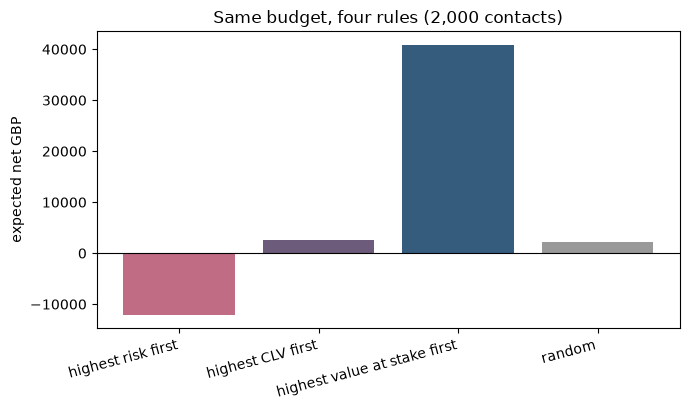

In [8]:
n_contacts = int(BUDGET // COST_PER_CONTACT)
full["recovered"] = SAVE_RATE * full["at_stake"]
rng = np.random.default_rng(42)
ranks = {"highest risk first":          full["risk"].rank(ascending=False, method="first"),
         "highest CLV first":           full["clv"].rank(ascending=False, method="first"),
         "highest value at stake first": full["at_stake"].rank(ascending=False, method="first"),
         "random":                      pd.Series(rng.permutation(len(full)) + 1, index=full.index)}
rows = []
for name, rk in ranks.items():
    sel = rk <= n_contacts
    rows.append({"strategy": name, "contacted": int(sel.sum()), "cost": int(sel.sum() * COST_PER_CONTACT),
                 "expected_recovered": full.loc[sel, "recovered"].sum(),
                 "net": full.loc[sel, "recovered"].sum() - sel.sum() * COST_PER_CONTACT,
                 "mean_risk": full.loc[sel, "risk"].mean(), "mean_clv": full.loc[sel, "clv"].mean(),
                 "share_high_risk_low_value": ((full.loc[sel, "band"] == "high") & full.loc[sel, "tier"].isin(["Q1 lowest", "Q2"])).mean()})
S = pd.DataFrame(rows)
print(S.round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(S["strategy"], S["net"], color=["#c06c84", "#6c5b7b", "#355c7d", "#999999"])
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("expected net GBP")
ax.set_title(f"Same budget, four rules ({n_contacts:,} contacts)")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.tight_layout(); fig.savefig("outputs/08_strategy_net.png", dpi=150); plt.show()
LOG["strategies"] = S.to_dict("records"); LOG["n_contacts"] = n_contacts

## Step 8. When is a segment not worth contacting?
A contact is worth it only if what it recovers on average beats what it costs. Break-even cost per contact for a cell = save rate x average value at stake per customer in that cell. A cell whose break-even is below the cost per contact should get nothing.

In [9]:
be = (SAVE_RATE * full.groupby(["band", "tier"], observed=True)["at_stake"].mean()).unstack()
print(f"break-even cost per contact, GBP, at save rate {SAVE_RATE:.0%} (cost used: {COST_PER_CONTACT})")
print(be.round(1).to_string())
print("\ncells worth contacting at the stated cost:")
print((be > COST_PER_CONTACT).to_string())
LOG["breakeven"] = be.round(1).reset_index().astype({"band": str}).to_dict("records")

break-even cost per contact, GBP, at save rate 15% (cost used: 25)
tier  Q1 lowest    Q2    Q3  Q4 top
band                               
low         3.2   7.9  11.0    10.3
mid         7.7  21.6  45.1   220.9
high       14.5  24.3  46.4    29.6

cells worth contacting at the stated cost:
tier  Q1 lowest     Q2     Q3  Q4 top
band                                 
low       False  False  False   False
mid       False  False   True    True
high      False  False   True    True


## Step 9. How much does the answer move with the three assumptions?
For each cost per contact and save rate, contact customers best-first by expected recovery until recovery per contact falls below the cost or the budget is spent. Print contacts and expected net.

In [10]:
rows = []
ranked = full["at_stake"].sort_values(ascending=False)
for cost in (10, 25, 50, 100):
    for s in (0.05, 0.10, 0.15, 0.25):
        g_ = s * ranked
        k = int(min(BUDGET // cost, (g_ > cost).sum()))
        rows.append({"cost_per_contact": cost, "save_rate": s, "contacts": k, "net": g_.head(k).sum() - k * cost})
SENS = pd.DataFrame(rows)
print(SENS.pivot(index="cost_per_contact", columns="save_rate", values="net").round(0).to_string())
print(SENS.pivot(index="cost_per_contact", columns="save_rate", values="contacts").to_string())
LOG["sens"] = SENS.to_dict("records")

save_rate            0.05     0.10     0.15      0.25
cost_per_contact                                     
10                12175.0  42279.0  79334.0  158016.0
25                 6031.0  20204.0  42290.0  101434.0
50                 5529.0  12062.0  23141.0   60877.0
100                5232.0  11057.0  17282.0   33068.0
save_rate         0.05  0.10  0.15  0.25
cost_per_contact                        
10                 999  2909  3528  4245
25                  49   698  1318  2000
50                  10    49   454   999
100                  4    10    21   229


## Step 10. DATA.md

In [11]:
marker = "## Act 3"
base = open("DATA.md").read().split(marker)[0].rstrip() + "\n\n"
sec = [marker + ": segments and retention budget", "",
 f"- Same cleaning and same BG/NBD as Act 2; total 12-month CLV {LOG['total_clv']:,.0f}",
 f"- Churn risk = probability of no order in the next {RISK_DAYS} days under BG/NBD (exact formula). Hidden-180-day check: predicted {LOG['bt_pred']:.1%} silent, actual {LOG['bt_act']:.1%}",
 f"- Value at stake = saveable risk x value if kept (average order value x order rate x {RISK_DAYS} days, undiscounted); total {LOG['at_stake']:,.0f}",
 f"- Rank correlation of risk with CLV: {LOG['rho']:.2f}",
 f"- Assumptions (invented, not from the data): budget {BUDGET:,} GBP, {COST_PER_CONTACT} GBP per contact, save rate {SAVE_RATE:.0%}",
 "- Risk bands: low below 25%, mid 25% to 60%, high above 60%; value tiers are the Act 2 CLV quartiles"]
open("DATA.md", "w").write(base + "\n".join(sec) + "\n")
print(open("DATA.md").read()[-1100:])
import json
json.dump(LOG, open("outputs/act3_log.json", "w"), default=float, indent=1)

rows: 802,634
- Unit: one customer, one order day; order days 32,878, customers 5,852
- Calibration ends 2011-06-12, holdout 180 days to 2011-12-09
- Horizon 12 months, discount 10% a year, revenue in GBP (no cost data, so not profit)
- Gamma-Gamma independence check: correlation of frequency and average order value among repeaters = 0.084
- Holdout revenue: predicted 3,779,301 vs actual 4,510,530
- Total 12-month CLV 8,888,115; top 10 percent of customers hold 60.3%

## Act 3: segments and retention budget

- Same cleaning and same BG/NBD as Act 2; total 12-month CLV 8,888,115
- Churn risk = probability of no order in the next 365 days under BG/NBD (exact formula). Hidden-180-day check: predicted 48.3% silent, actual 48.1%
- Value at stake = saveable risk x value if kept (average order value x order rate x 365 days, undiscounted); total 826,741
- Rank correlation of risk with CLV: -0.86
- Assumptions (invented, not from the data): budget 50,000 GBP, 25 GBP per contact, save rate 15%
-

## Limitations
1. The save rate, the cost per contact and the budget are invented. Nothing in this file says an offer keeps 15 percent of anyone. The recovered figure is a conditional: if the save rate were 15 percent, then this. A real number needs a controlled test, which is the uplift question in 26.03.
2. Risk and value come from the same model, so they are not independent. Customers that BG/NBD thinks are leaving are also the ones it values least, which is why the textbook cell (high risk and high value) is nearly empty here. The cross-tab shows that, it does not prove high-value customers never churn.
3. It says who is at risk, not why. A silent wholesale buyer may be seasonal, may have moved supplier, or may have gone bust, and each needs a different response. Also this is revenue not profit, value if kept assumes the customer keeps their own pace for a year, and one retailer over two years is the whole evidence.